# Bài 1C — Underfitting, Overfitting & Model Complexity với Decision Tree

## 1. Mục Tiêu Bài Học
- **Hiểu bản chất Underfitting & Overfitting:** Quan sát sự biến thiên của hiệu năng trên tập Train và Validation khi độ phức tạp mô hình thay đổi.
- **Thực nghiệm với Decision Tree Classifier:** Điều chỉnh siêu tham số độ sâu tối đa (`max_depth`) từ rất nông (cây đơn giản) đến không giới hạn (cây phức tạp tối đa).
- **Vẽ đường cong Validation Curve:** Trực quan hóa điểm đánh đổi Bias–Variance (*Bias-Variance Tradeoff*) và xác định "điểm ngọt" (*Sweet Spot*).
- **Phân tích thước đo:** Đối chiếu giữa **ROC-AUC** và **Accuracy** trên dữ liệu mất cân bằng.
- **Tuân thủ kỷ luật ML:** Tiếp tục **niêm phong tập Test**, toàn bộ quá trình thử nghiệm chỉ thực hiện trên tập Train và Validation.

## 2. Chuẩn Bị Dữ Liệu & Tiền Xử Lý Cơ Bản

Kế thừa nguyên tắc từ Bài 1B:
1. Loại bỏ đặc trưng `duration` để chống **Data Leakage**.
2. Phân chia dữ liệu phân tầng: Train (70%), Validation (15%), Test (15%).
3. Mã hóa các biến phân loại (`OneHotEncoder`): **Chỉ `fit` trên tập Train** để tránh rò rỉ phân phối sang tập Validation.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, accuracy_score

# 1. Đọc dữ liệu
data_path = Path("data/raw/bank-additional-full.csv")
if Path.cwd().name == "notebooks":
    data_path = Path("../data/raw/bank-additional-full.csv")

df = pd.read_csv(data_path, sep=";")

# 2. Tách biến và loại bỏ duration
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

# 3. Phân chia phân tầng: Train (70%), Val (15%), Test (15%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
val_ratio = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_ratio, random_state=42, stratify=y_temp
)

print(f"Kích thước X_train: {X_train.shape}, X_val: {X_val.shape}")

Kích thước X_train: (28830, 19), X_val: (6179, 19)


### Mã hóa đặc trưng phân loại bằng OneHotEncoder
*Lưu ý: Chỉ `fit` bộ encoder trên `X_train`, sau đó dùng lại để `transform` cho `X_train` và `X_val`.*

In [2]:
cat_cols = X_train.select_dtypes(include=["object", "str", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

# Fit encoder trên Train
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[cat_cols])

# Transform cho cả Train và Val
X_train_encoded = np.hstack([X_train[num_cols].values, encoder.transform(X_train[cat_cols])])
X_val_encoded = np.hstack([X_val[num_cols].values, encoder.transform(X_val[cat_cols])])

print(f"Số lượng đặc trưng sau OneHotEncoding: {X_train_encoded.shape[1]}")

Số lượng đặc trưng sau OneHotEncoding: 62


## 3. Huấn Luyện Decision Tree Với Các Giá Trị `max_depth` Khác Nhau

Chúng ta khảo sát dải giá trị độ sâu `max_depth` từ 1 (rất nông) đến `None` (cây phát triển tự do không giới hạn, các lá thuần khiết 100%).
Ở mỗi mức độ sâu, ta ghi nhận kết quả **ROC-AUC** và **Accuracy** trên cả hai tập Train và Validation.

In [3]:
from IPython.display import display

depths = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20, None]
results = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train_encoded, y_train)
    
    # Dự đoán xác suất cho ROC-AUC
    train_proba = clf.predict_proba(X_train_encoded)[:, 1]
    val_proba = clf.predict_proba(X_val_encoded)[:, 1]
    
    # Dự đoán nhãn cho Accuracy
    train_pred = clf.predict(X_train_encoded)
    val_pred = clf.predict(X_val_encoded)
    
    train_auc = roc_auc_score(y_train, train_proba)
    val_auc = roc_auc_score(y_val, val_proba)
    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)
    
    d_label = str(d) if d is not None else "None (Max)"
    results.append({
        "max_depth": d_label,
        "Train ROC-AUC": round(train_auc, 4),
        "Val ROC-AUC": round(val_auc, 4),
        "Train Accuracy": round(train_acc, 4),
        "Val Accuracy": round(val_acc, 4),
        "Gap (Train - Val AUC)": round(train_auc - val_auc, 4)
    })

results_df = pd.DataFrame(results)
display(results_df)

,max_depth,Train ROC-AUC,Val ROC-AUC,Train Accuracy,Val Accuracy,Gap (Train - Val AUC)
0,1,0.6994,0.6959,0.8873,0.8874,0.0035
1,2,0.7460,0.7374,0.8994,0.8984,0.0086
2,3,0.7524,0.7456,0.8996,0.8993,0.0068
3,4,0.7595,0.7498,0.9009,0.8992,0.0097
4,5,0.7857,0.7710,0.9031,0.8987,0.0147
5,6,0.7946,0.7775,0.9044,0.8979,0.0171
6,7,0.8041,0.7708,0.9072,0.8979,0.0334
7,8,0.8138,0.7615,0.9103,0.8976,0.0522
8,10,0.8404,0.7227,0.9190,0.8919,0.1177
9,12,0.8705,0.6677,0.9299,0.8890,0.2028


## 4. Trực Quan Hóa Đường Cong Độ Phức Tạp (Validation Curve)

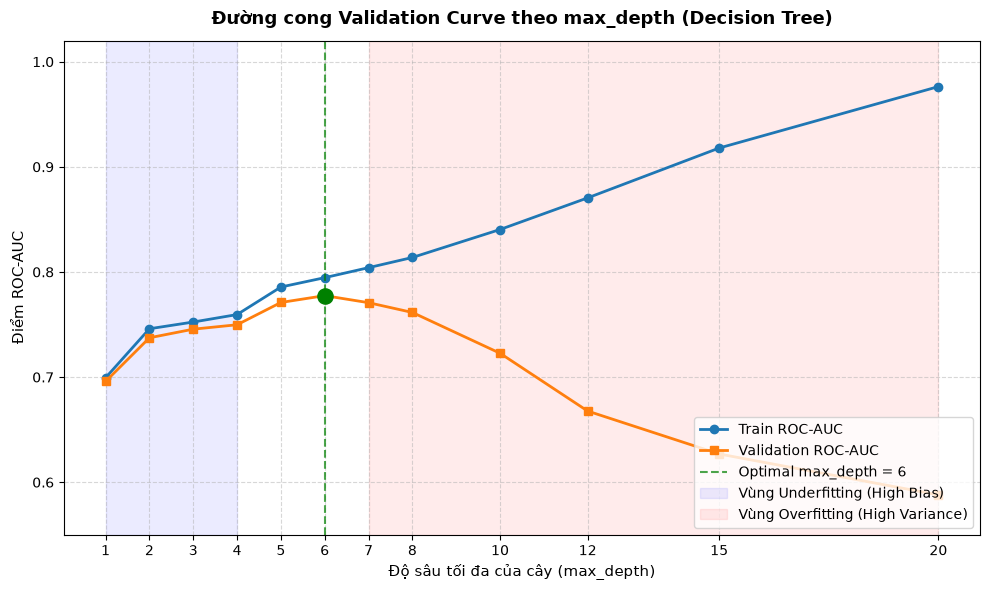

In [4]:
# Chuẩn bị dữ liệu vẽ đồ thị (loại bỏ None để hiển thị trục số liên tục)
numeric_depths = [d for d in depths if d is not None]
train_aucs = [r["Train ROC-AUC"] for r in results if r["max_depth"] != "None (Max)"]
val_aucs = [r["Val ROC-AUC"] for r in results if r["max_depth"] != "None (Max)"]

plt.figure(figsize=(10, 6))
plt.plot(numeric_depths, train_aucs, marker="o", label="Train ROC-AUC", color="#1f77b4", linewidth=2)
plt.plot(numeric_depths, val_aucs, marker="s", label="Validation ROC-AUC", color="#ff7f0e", linewidth=2)

# Đánh dấu điểm tối ưu (Sweet spot)
best_idx = np.argmax(val_aucs)
best_depth = numeric_depths[best_idx]
best_val_auc = val_aucs[best_idx]
plt.axvline(x=best_depth, color="green", linestyle="--", alpha=0.7, label=f"Optimal max_depth = {best_depth}")
plt.scatter([best_depth], [best_val_auc], color="green", s=120, zorder=5)

# Vùng Underfitting và Overfitting
plt.axvspan(1, 4, color="blue", alpha=0.08, label="Vùng Underfitting (High Bias)")
plt.axvspan(7, 20, color="red", alpha=0.08, label="Vùng Overfitting (High Variance)")

plt.title("Đường cong Validation Curve theo max_depth (Decision Tree)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Độ sâu tối đa của cây (max_depth)", fontsize=11)
plt.ylabel("Điểm ROC-AUC", fontsize=11)
plt.xticks(numeric_depths)
plt.ylim(0.55, 1.02)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

## 5. Phân Tích & Đánh Giá Chuyên Sâu (Critical ML Analysis)

### 1. Vấn đề Khái Quát Hóa (Generalization):
- **Quan sát:** Trong phạm vi các cấu hình đã thử nghiệm, **`max_depth = 6` đạt kết quả cao nhất trên tập Validation cụ thể này (Val ROC-AUC ≈ 0.7775)**.
- **Lưu ý quan trọng về phương pháp luận:** Kết quả này **chưa thể khẳng định** mô hình sẽ hoạt động tốt nhất trên mọi dữ liệu thực tế trong tương lai.
  - Một tập Validation đơn lẻ (*single hold-out*) chịu ảnh hưởng của tính ngẫu nhiên khi chia tách dữ liệu.
  - Việc thử nhiều siêu tham số rồi chọn cấu hình cao nhất có thể gây ra hiện tượng **Overfitting vào chính tập Validation** (*Validation Leakage*).
  - Để đánh giá độ tin cậy thực sự, cần áp dụng **K-Fold Cross-Validation** (đo độ ổn định phương sai) và kiểm tra cuối cùng trên **tập Test độc lập (Sealed Test Set)**.

### 2. Hiện tượng Overfitting & Giải mã Train Accuracy 99.55% (Tại sao không đạt 100% khi `max_depth = None`?):
- Khi `max_depth = None`, cây phân nhánh tự do nhưng **Train Accuracy chỉ đạt 99.55% chứ không phải 100%**.
- **Nguyên nhân cốt lõi:** Trong tập dữ liệu Train có **128 nhóm gồm 282 mẫu có bộ đặc trưng X giống hệt nhau 100% nhưng mang nhãn y trái ngược nhau** (người đồng ý gửi, người từ chối).
  - Decision Tree không thể tìm thấy bất kỳ nhát cắt nào trên bất kỳ thuộc tính nào để phân tách các mẫu có cùng giá trị X.
  - Khi độ giảm độ bất thuần (*impurity decrease*) bằng 0, thuật toán bắt buộc phải dừng tách nút đó theo điều kiện dừng mặc định (`min_impurity_decrease = 0.0`) và gán nhãn theo số đông tại nút lá, dẫn đến sai sót không thể tránh khỏi trên các mẫu còn lại.

### 3. Phân biệt Bản Chất Giữa ROC-AUC, PR-AUC và Recall trên Dữ Liệu Mất Cân Bằng:
- **ROC-AUC (Receiver Operating Characteristic):** Đánh giá khả năng xếp hạng tổng thể (xác suất mẫu dương được xếp hạng cao hơn mẫu âm).
  - Tuy nhiên, mẫu số của False Positive Rate (FPR = FP / (FP + TN)) chứa số lượng TN khổng lồ (lớp `no` chiếm ~89%). Điều này khiến FPR luôn bị đè ở mức rất nhỏ dù số lượng dự đoán sai FP có thể rất lớn, tạo nên góc nhìn **quá lạc quan** (*overly optimistic*).
  - Ngoài ra, ROC-AUC không phụ thuộc ngưỡng (*threshold-agnostic*), do đó **không cho biết ở một ngưỡng cụ thể**, ngân hàng bắt được bao nhiêu khách hàng `yes`.
- **Recall (TP / (TP + FN)):** Trả lời câu hỏi kinh doanh cốt lõi: *"Trong số tất cả khách hàng thực tế đồng ý, ngân hàng bắt trúng được bao nhiêu %?"* tại một ngưỡng cắt cụ thể.
- **PR-AUC (Precision-Recall AUC):** Tập trung trực tiếp vào mối quan hệ giữa Precision và Recall mà **hoàn toàn không bị ảnh hưởng bởi TN**. Đây là thước đo đối chuẩn chuẩn xác hơn nhiều khi so sánh các mô hình trên tập dữ liệu mất cân bằng.